# Lab: Relationships Between Categorical Features

Imagine James Cameron has hired you to develop two character profiles for a Titanic movie reboot: one “most likely to survive” and one “least likely to survive.” Support both profiles with passenger data and visualizations, then connect them to real people and their biographies.

These labels describe profiles suggested by observed group survival percentages in this dataset. They are not guaranteed individual outcomes, a validated prediction model, or proof that any feature caused survival.


## Learning goals

- Apply the six-step analysis workflow to categorical comparisons.
- Justify categories created from age and travel-companion counts.
- Distinguish raw counts from survival percentages within groups.
- Build clearly labeled figures and check their meaning.
- Support character profiles with evidence and identify matching passengers.
- Connect data records to cited historical biographies.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do the original values support the coding and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Use one six-step workflow for the complete character-profile investigation. All six feature comparisons belong together in Step 3: Evidence.


## Dataset and scope

Use the supplied `data/titanic_passengers.csv`, the 891-row training dataset from [Kaggle Titanic: Machine Learning from Disaster](https://www.kaggle.com/c/titanic/data). Each row represents a passenger in this file; it is not a complete passenger-and-crew list. Consult the source dictionary when interpreting the features.

Analyze only categorical comparisons with `Survived`. Use `Pclass` instead of `Fare`; do not analyze fare. Age is the exception: convert it to justified categories before comparing survival. Treat travel-companion counts as categories, combining sparse groups if appropriate. Use names and passenger IDs only to identify people.

| Feature | Meaning and role |
| --- | --- |
| `Survived` | Categorical outcome: 0 = did not survive, 1 = survived |
| `Pclass` | Ordered passenger class: 1, 2, or 3; categorical despite numeric storage |
| `Sex` | Recorded sex category |
| `Age` | Age in years; use only through your chosen age groups |
| `Parch` | Count of parents/children aboard; use as categories or collapse into groups |
| `SibSp` | Count of siblings/spouse aboard; use as categories or collapse into groups |
| `Embarked` | Embarkation port: C = Cherbourg, Q = Queenstown, S = Southampton |
| `Name`, `PassengerId` | Passenger identification for matching records to biographies |

The file also contains `Ticket`, `Fare`, and `Cabin`; do not use them as comparison features in this lab.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code and checking claims against the output. Read the actual Encyclopedia Titanica biographies rather than using an uncited AI-generated fact. Disclose AI use in the final reflection.


## Step 1: Question

**Which categorical characteristics support a “most likely to survive” profile and a “least likely to survive” profile in this Titanic dataset?**

Consider age group, sex, passenger class, parents/children aboard, siblings/spouse aboard, and embarkation port together as parts of this one investigation.


**Before examining survival percentages, describe your predicted high-survival and low-survival profiles. What reasoning or prior knowledge supports your predictions?**

Your answer: After the lecture we know that females are most likely to survive and people with 1 parent/child are most likely to survive. Honestly without that information my guess would have been identical because of the movie. Save the women and children first. 


## Step 2: Data


## Load and inspect the data

Use `titanic_df` as the DataFrame name. Keep the original columns so your category choices can be checked.


In [2]:
# Import pandas as pd and matplotlib.pyplot as plt.
import pandas as pd 
import matplotlib.pyplot as plt 


In [3]:
# Read data/titanic_passengers.csv into titanic_df.
titanic_df = pd.read_csv('data/titanic_passengers.csv')

In [4]:
# Display the first five rows.
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
# Display .info().
titanic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
# Display the missing-value count for each feature.
titanic_df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

**What does one row represent? Which feature is the target, and what do its codes mean?**

Your answer: A row can represent different things depending on what table you're looking at. For example, looking at #titanic_df.head() the row would give a passenger and all of the data collected to each feature. If you're looking at #titanic_df.info() then a row would give you a feature name and some information that goes along with that feature like data type and the non null count of entries throughout the database. The target feature can be any feature that you want to identify correspondeses with, for the extent of this lab I imagine the target feature is Survived. The Survived feature stores an int64 with entries either being 0 or 1 where 0 would represent not survived and 1 representing survived. 


Complete this table from the inspection. Distinguish a feature's meaning from its Pandas storage type; numeric codes can represent categories.


| Feature | Data type (categorical/quantitative/identifier) | Data storage type | Missing values |
| --- | --- | --- | ---: |
| `PassengerId` | identifier| int64 | 0 |
| `Name` |identifier| object | 0 |
| `Survived` | categorical| int64 | 0 |
| `Pclass` |categorical | int64 |0  |
| `Sex` | categorical|  object|0  |
| `Age` | quantitative| float64 | 177 |
| `Parch` | quantitative | int64 | 0 |
| `SibSp` | quantitative|  int64|0  |
| `Embarked` |categorical| object | 2 |


## Plan your age groups before comparing survival

Choose your own age categories. You might use children versus adults, split at 16, 18, or 20, or define several groups such as children, teens, young adults, and older adults. There is no single required cutoff. Give a reasoned argument based on the meaning of the groups and their usefulness, not just which split produces the strongest survival difference.

Write exact boundaries, including where an age exactly at a cutoff belongs. Cover all known ages without overlapping groups. Preserve unknown ages as missing or label them “Unknown”; do not accidentally classify them as adults. If you exclude unknown ages from this comparison, state that denominator choice. Do not guess an age from whether someone survived.


| Age-group label | Exact rule (including boundary values) | Reason for this choice |
| --- | --- | --- |
| Young_Child | 0-12 | To see if their was a president for whether or not younger or older children took priority |
| Older_Child | 12-18 | To see if their was a president for whether or not older children took priority or were considered close enough to adulthood |
| Young Adult | 18-25 | To see if there is a president over young adults vs Older adults | 
| Adults | 25+ | To ultimately capture everyone else | 

Add rows if needed.


**Why are your age groups reasonable? How will you handle unknown ages, and why?**

Your answer: My age groups should create enough of a seperation to gather evidence to see at which point were individuals more likely to survive. 


Create `age_group` using `.loc` or `pd.cut`. If using `.loc`, initialize the column to an explicit “Unknown” label and assign labels only where ages satisfy your rules. If using `pd.cut`, choose its interval boundaries carefully and document whether intervals include their right or left endpoint. Count the observations in each category, including unknowns.


In [12]:
# Create age_group and display its category counts, including unknown ages.
titanic_df.loc[titanic_df['Age'] > 0 , 'age_group'] = 0
titanic_df.loc[titanic_df['Age'] > 12, 'age_group'] = 1
titanic_df.loc[titanic_df['Age'] > 18, 'age_group'] = 2
titanic_df.loc[titanic_df['Age'] > 25, 'age_group'] = 3
titanic_df.loc[titanic_df['Age'].isna(), 'age_group'] = 4


pd.crosstab(titanic_df['Age'], titanic_df['age_group'])
titanic_df['age_group'].value_counts(dropna=False)


age_group
3.0    413
4.0    177
2.0    162
1.0     70
0.0     69
Name: count, dtype: int64

**Are any age groups very small? Would a different grouping be more useful? Explain any revision before comparing survival.**

Your answer: The smallest age group, young children, consists of 69 entries but I think that metric is significant enough to still have value in the comparison. 


### Choose travel-companion categories

Inspect the frequencies of `Parch` and `SibSp`. Treat their values as discrete categories or collapse them into meaningful groups, such as none/any or none/one/two or more. Explain your choices, particularly when some categories have few passengers. Preserve the original columns.


In [13]:
# Display Parch and SibSp category counts; create any grouped features and display their counts.
titanic_df.loc[titanic_df['SibSp'] == 0, 'SibSp_group'] = 'None'
titanic_df.loc[titanic_df['SibSp'] == 1, 'SibSp_group'] = 'One'
titanic_df.loc[titanic_df['SibSp'] >= 2, 'SibSp_group'] = 'Two or More'

titanic_df.loc[titanic_df['Parch'] == 0, 'Parch_group'] = 'None'
titanic_df.loc[titanic_df['Parch'] == 1, 'Parch_group'] = 'One'
titanic_df.loc[titanic_df['Parch'] >= 2, 'Parch_group'] = 'Two or More'

print(titanic_df['SibSp_group'].value_counts())
print(titanic_df['Parch_group'].value_counts())


SibSp_group
None           608
One            209
Two or More     74
Name: count, dtype: int64
Parch_group
None           678
One            118
Two or More     95
Name: count, dtype: int64


**What travel-companion groups will you use, and why? State any exclusions and how you will handle unknown embarkation ports. Which observations form the denominator for each comparison?**

Your answer: I will use Parch groups becuase I think the weight of the assesment will speak greater value to the evidence and draw a stronger conclusion. I will handle unknown embarkation ports when it comes up and I understand more the significance of that variable. In both observations the denominator are those with 2 or more travel companions.


## Step 3: Evidence

Bring all six feature comparisons together here. For each feature:

- Display a count cross-tab with comparison categories in rows and survival outcomes in columns.
- Calculate survival percentages within each comparison group and display only the percentage who survived (column `1`). Keep group counts available for context.
- Make a bar chart of the conditional percentage who survived, with a meaningful title, descriptive axes, readable category labels, and named colors. Use a 0–100 percentage scale and `plt.legend()` if a legend is needed. Move it outside the axes if it covers the data.

Use separate code cells for the individual operations and add cells as needed. The subsections below organize the evidence; they are not separate workflows.


### Age groups

Compare `age_group` with `Survived` using your Data-step choices.


In [14]:
# Create and display the count cross-tab.
pd.crosstab(titanic_df['age_group'], titanic_df['Survived'])

Survived,0,1
age_group,,
0.0,29,40
1.0,40,30
2.0,108,54
3.0,247,166
4.0,125,52


In [16]:
# Calculate conditional percentages and display only the survived column.
pd.crosstab(titanic_df['age_group'], titanic_df['Survived'], normalize='index').mul(100)[1]

age_group
0.0    57.971014
1.0    42.857143
2.0    33.333333
3.0    40.193705
4.0    29.378531
Name: 1, dtype: float64

For age groups, also display joint percentages (`normalize="all"`, multiplied by 100) and make a count chart showing both outcomes. Compare this with the survivor-percentage chart to distinguish counts, joint percentages, and within-group percentages.


In [17]:
# Display joint percentages, then create a count chart in a separate cell.
# Assuming 'Survived' has values 0 (Died) and 1 (Survived)
joint_matrix = pd.crosstab(
    titanic_df['age_group'], 
    titanic_df['Survived'], 
    normalize="all"
) * 100

print("--- Joint Percentages (% of Total Dataset) ---")
print(joint_matrix.round(2))


--- Joint Percentages (% of Total Dataset) ---
Survived       0      1
age_group              
0.0         3.25   4.49
1.0         4.49   3.37
2.0        12.12   6.06
3.0        27.72  18.63
4.0        14.03   5.84


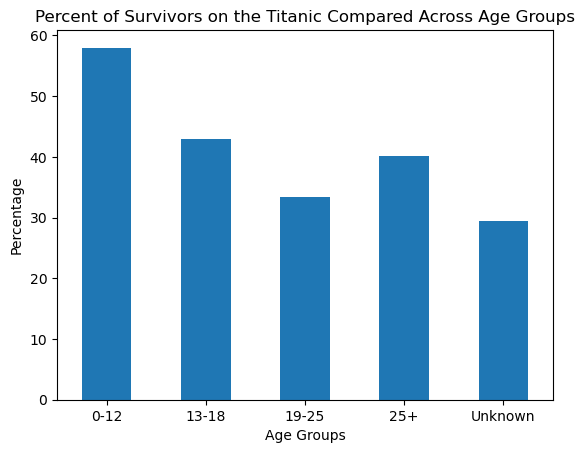

In [20]:
# Plot the conditional percentage who survived.
pd.crosstab(titanic_df['age_group'], titanic_df['Survived'], normalize='index').mul(100)[1].plot(kind='bar')
plt.title('Percent of Survivors on the Titanic Compared Across Age Groups')
plt.ylabel('Percentage')
plt.xlabel('Age Groups')
plt.xticks([0, 1, 2, 3, 4], ['0-12', '13-18', '19-25', '25+', 'Unknown'], rotation=0)
plt.show()

### Sex

Compare `Sex` with `Survived` using your Data-step choices.


In [21]:
# Create and display the count cross-tab.
pd.crosstab(titanic_df['Sex'], titanic_df['Survived'])

Survived,0,1
Sex,,
female,81,233
male,468,109


In [22]:
# Calculate conditional percentages and display only the survived column.
pd.crosstab(titanic_df['Sex'], titanic_df['Survived'], normalize='index').mul(100)[1]

Sex
female    74.203822
male      18.890815
Name: 1, dtype: float64

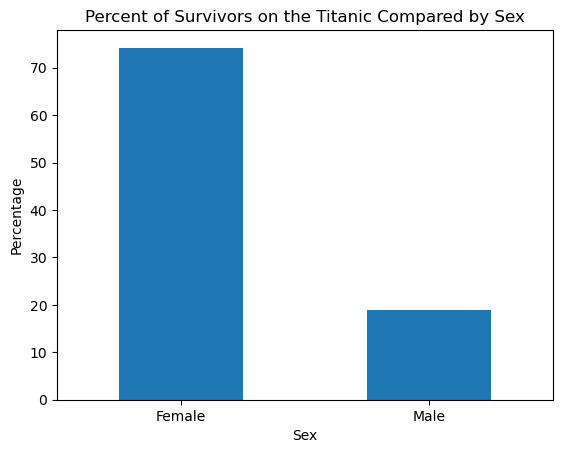

In [24]:
# Plot the conditional percentage who survived.
pd.crosstab(titanic_df['Sex'], titanic_df['Survived'], normalize='index').mul(100)[1].plot(kind='bar')
plt.title('Percent of Survivors on the Titanic Compared by Sex')
plt.ylabel('Percentage')
plt.xlabel('Sex')
plt.xticks([0,1], ['Female', 'Male'], rotation=0)
plt.show()

### Passenger class

Compare `Pclass` with `Survived` using your Data-step choices.


In [25]:
# Create and display the count cross-tab.
pd.crosstab(titanic_df['Pclass'], titanic_df['Survived'])

Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


In [26]:
# Calculate conditional percentages and display only the survived column.
pd.crosstab(titanic_df['Pclass'], titanic_df['Survived'], normalize='index').mul(100)[1]

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: 1, dtype: float64

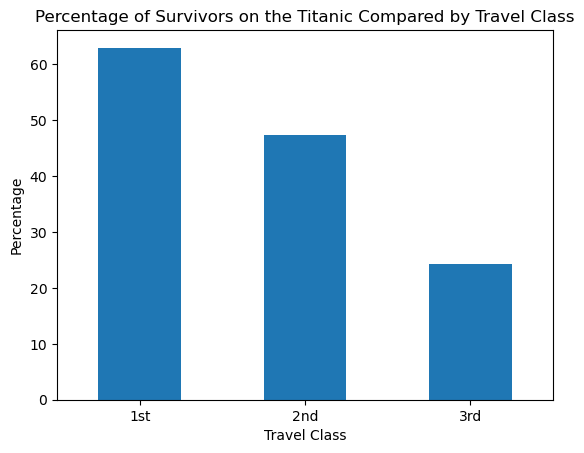

In [27]:
# Plot the conditional percentage who survived.
pd.crosstab(titanic_df['Pclass'], titanic_df['Survived'], normalize='index').mul(100)[1].plot(kind='bar')
plt.title('Percentage of Survivors on the Titanic Compared by Travel Class')
plt.ylabel('Percentage')
plt.xlabel('Travel Class')
plt.xticks([0,1,2],['1st','2nd','3rd'],rotation=0)
plt.show()

### Parents or children aboard

Compare `Parch or your derived group` with `Survived` using your Data-step choices.


In [29]:
# Create and display the count cross-tab.
pd.crosstab(titanic_df['Parch_group'], titanic_df['Survived'])

Survived,0,1
Parch_group,,
None,445,233
One,53,65
Two or More,51,44


In [30]:
# Calculate conditional percentages and display only the survived column.
pd.crosstab(titanic_df['Parch_group'], titanic_df['Survived'], normalize='index').mul(100)[1]

Parch_group
None           34.365782
One            55.084746
Two or More    46.315789
Name: 1, dtype: float64

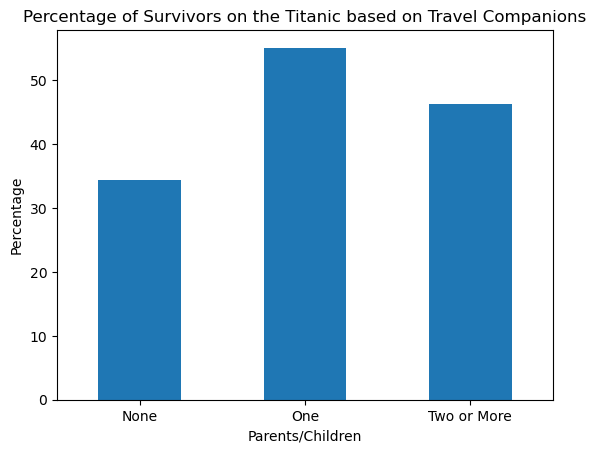

In [31]:
# Plot the conditional percentage who survived.
pd.crosstab(titanic_df['Parch_group'], titanic_df['Survived'], normalize='index').mul(100)[1].plot(kind='bar')
plt.title('Percentage of Survivors on the Titanic based on Travel Companions')
plt.ylabel('Percentage')
plt.xlabel('Parents/Children')
plt.xticks([0,1,2],['None','One','Two or More'],rotation=0)
plt.show()

### Siblings or spouse aboard

Compare `SibSp or your derived group` with `Survived` using your Data-step choices.


In [32]:
# Create and display the count cross-tab.
pd.crosstab(titanic_df['SibSp_group'], titanic_df['Survived'])

Survived,0,1
SibSp_group,,
None,398,210
One,97,112
Two or More,54,20


In [33]:
# Calculate conditional percentages and display only the survived column.
pd.crosstab(titanic_df['SibSp_group'], titanic_df['Survived'],normalize='index').mul(100)[1]

SibSp_group
None           34.539474
One            53.588517
Two or More    27.027027
Name: 1, dtype: float64

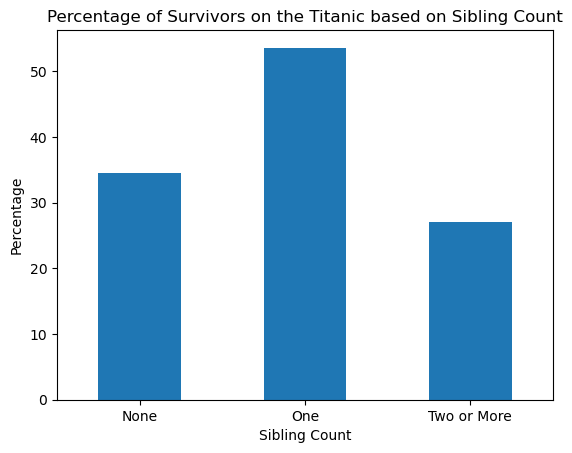

In [34]:
# Plot the conditional percentage who survived.
pd.crosstab(titanic_df['SibSp_group'], titanic_df['Survived'],normalize='index').mul(100)[1].plot(kind='bar')
plt.title('Percentage of Survivors on the Titanic based on Sibling Count')
plt.ylabel('Percentage')
plt.xlabel('Sibling Count')
plt.xticks([0,1,2],['None','One','Two or More'],rotation=0)
plt.show()

### Embarkation port

Compare `Embarked` with `Survived` using your Data-step choices.


In [36]:
# Create and display the count cross-tab.
pd.crosstab(titanic_df['Embarked'],titanic_df['Survived'])

Survived,0,1
Embarked,,
C,75,93
Q,47,30
S,427,217


In [38]:
# Calculate conditional percentages and display only the survived column.
pd.crosstab(titanic_df['Embarked'],titanic_df['Survived'],normalize='index').mul(100)[1]

Embarked
C    55.357143
Q    38.961039
S    33.695652
Name: 1, dtype: float64

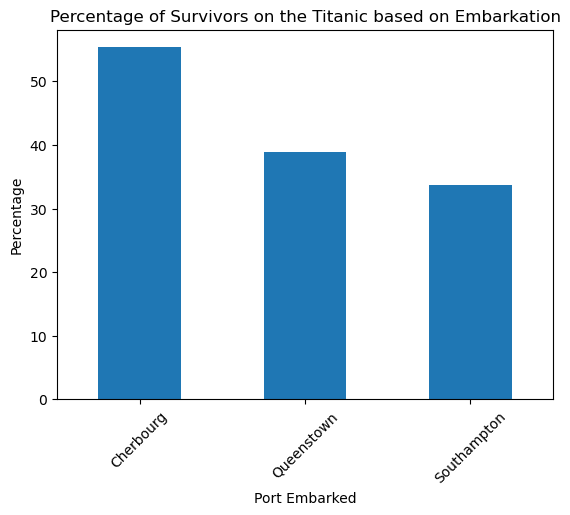

In [39]:
# Plot the conditional percentage who survived.
pd.crosstab(titanic_df['Embarked'],titanic_df['Survived'],normalize='index').mul(100)[1].plot(kind='bar')
plt.title('Percentage of Survivors on the Titanic based on Embarkation')
plt.ylabel('Percentage')
plt.xlabel('Port Embarked')
plt.xticks([0,1,2],['Cherbourg','Queenstown','Southampton'],rotation=45)
plt.show()

### Summarize the evidence

Record the highest- and lowest-survival categories for each feature. Include percentages and group sizes; mention ties or very small groups that affect interpretation.


| Feature | Highest-survival category, percentage, and group size | Lowest-survival category, percentage, and group size |
| --- | --- | --- |
| Sex (example) | Female: 74.2% survived (233 of 314 passengers). | Male: 18.9% survived (109 of 577 passengers). |
| Age groups | Young Children 0-12: 57.97% (40 out of 69 passengers) | Uknown: 29.37% (52 out of 177 passengers) |
| Passenger class | 1st class: 62.96% (136 out of 216 passengers) | 3rd class: 24.23% (119 out of 491 passengers) |
| Parents or children aboard | One parent or child: 55.08% ( 65 out of 138 passengers) | None: 34.36% (233 out of 678 passengers) |
| Siblings or spouse aboard |One sibling or Spouse: 53.58% survived (112 out of 209 passengers)  | Two or More: 27.02% (20 out of 74 passengers) |
| Embarkation port |Cherbourg: 55.35% survived (93 out of 148 passengers)  | Southampton: 33.69% survived (217 out of 644) |


**Using the age comparison, interpret one joint percentage and one conditional percentage. What denominator does each use, and which figure answers the survival-likelihood question more clearly?**

Your answer: 
If you only looked at joint percentages, you might assume that being in the 3.0 group (aged 25+) was safer because they represent a massive 18.63% of the entire ship's survivors, whereas children (0.0) represent a tiny 4.49% of the ship's survivors.

The conditional percentage completely flips this. A child had a 57.97% survival rate, while an adult over 25 only had a 40.19% survival rate.
The joint percentage for children is small simply because there weren't many children on board to begin with, not because their survival odds were poor. The conditional percentage flattens out that population difference and proves that children were prioritized.


## Step 4: Check

Check the meaning of your combined evidence, rather than repeating the initial row count or missing-value inspection.

- Compare each age group's minimum and maximum known ages with your declared boundaries, including exact cutoffs and unknown ages.
- If you collapsed travel-companion categories, cross-tab the original counts against your group labels.
- Check that percentages use all passengers in the relevant group, not just survivors. Compare the direction of the percentages with the count tables.
- Identify sparse groups or implausible values that deserve caution.


In [40]:
# Check age-group boundaries and unknown ages.
age_summary = titanic_df.groupby('age_group')['Age'].agg(['min', 'max'])

print(age_summary)


             min   max
age_group             
0.0         0.42  12.0
1.0        13.00  18.0
2.0        19.00  25.0
3.0        26.00  80.0
4.0          NaN   NaN


In [42]:
# Check travel-companion category mappings if you created grouped features.
parch_summary = titanic_df.groupby('Parch_group')['Parch'].agg(['min','max'])

print(parch_summary)

             min  max
Parch_group          
None           0    0
One            1    1
Two or More    2    6


**Do the age boundaries, category mappings, and denominators match your intentions? What would make you suspicious, and did you find or correct any issues? Which small groups limit interpretation?**

Your answer: Yes this all matched my intentions and the outcomes were predictable. The only corrections that had to be made were syntax errors that were corrected along the way. I'm not sure if there were any small groups that limited interpretation. 


## Step 5: Conclusion

Use the combined evidence to develop the two profiles, find matching passengers, and connect them to historical biographies.


### Build your two character profiles

Combine the evidence into a “most likely to survive” profile and a “least likely to survive” profile. Include all six elements. Cite the relevant group percentage and size for each choice. Do not multiply separate feature percentages to produce an individual survival probability: the features may be related, and separate comparisons do not establish the survival rate for their combination.


| Profile element | Most likely profile: category and evidence | Least likely profile: category and evidence |
| --- | --- | --- |
| Sex (example) | Female: 74.2% survived (233 of 314 passengers). | Male: 18.9% survived (109 of 577 passengers). |
| Age groups | Young Children 0-12: 57.97% (40 out of 69 passengers) | Uknown: 29.37% (52 out of 177 passengers) |
| Passenger class | 1st class: 62.96% (136 out of 216 passengers) | 3rd class: 24.23% (119 out of 491 passengers) |
| Parents or children aboard | One parent or child: 55.08% ( 65 out of 138 passengers) | None: 34.36% (233 out of 678 passengers) |
| Siblings or spouse aboard |One sibling or Spouse: 53.58% survived (112 out of 209 passengers)  | Two or More: 27.02% (20 out of 74 passengers) |
| Embarkation port |Cherbourg: 55.35% survived (93 out of 148 passengers)  | Southampton: 33.69% survived (217 out of 644) |



In [54]:
most_likely_mask = (
    (titanic_df['Sex'] == 'female') &
    (titanic_df['age_group'] == 0) &
    (titanic_df['Parch_group'] == 'One') &
    (titanic_df['SibSp_group'] == 'One') 
)

most_likely_passengers = titanic_df.loc[most_likely_mask]
most_likely_passengers.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,age_group,SibSp_group,Parch_group
10,11,1,3,"Sandstrom, Miss. Marguerite Rut",female,4.0,1,1,PP 9549,16.7000,G6,S,0.0,One,One
172,173,1,3,"Johnson, Miss. Eleanor Ileen",female,1.0,1,1,347742,11.1333,NaN,S,0.0,One,One
530,531,1,2,"Quick, Miss. Phyllis May",female,2.0,1,1,26360,26.0000,NaN,S,0.0,One,One
750,751,1,2,"Wells, Miss. Joan",female,4.0,1,1,29103,23.0000,NaN,S,0.0,One,One
852,853,0,3,"Boulos, Miss. Nourelain",female,9.0,1,1,2678,15.2458,NaN,C,0.0,One,One


In [55]:
least_likely_mask = (
    (titanic_df['Sex'] == 'male') &
    (titanic_df['age_group'] == 4) &
    (titanic_df['Pclass'] == 3) &
    (titanic_df['Parch_group'] == 'None') &
    (titanic_df['SibSp_group'] == 'Two or More') )

least_likely_passengers = titanic_df.loc[least_likely_mask]
least_likely_passengers[['Name', 'Age', 'Pclass', 'Survived']]
least_likely_passengers.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,age_group,SibSp_group,Parch_group
48,49,0,3,"Samaan, Mr. Youssef",male,NaN,2,0,2662,21.6792,NaN,C,4.0,Two or More,None
301,302,1,3,"McCoy, Mr. Bernard",male,NaN,2,0,367226,23.2500,NaN,Q,4.0,Two or More,None


**Write a short character description for each profile. Explain any tradeoffs where the evidence does not point to a single obvious combination.**

Your answer: I'm not sure how to answer this question honestly. I'm confused by what is being asked of me. 

### Find real passengers who fit

Use Boolean conditions with `.loc` to find passengers matching each profile across all six elements. Save the results as `most_likely_df` and `least_likely_df`, and display their names and the features used to match them. **Do not filter on `Survived` to build these lists**: an actual outcome is not a profile characteristic.

If a list is empty, explain which combination has no matching record, then revise and justify your profile transparently using the evidence. Keep all six elements in your revised profile, update the profile table, and rerun the filter. Do not silently drop a condition or invent a passenger. You need at least one matching person in each list.


In [56]:
# Create most_likely_df and display matching names and profile features.
most_likely_mask = (
    (titanic_df['Sex'] == 'female') &
    (titanic_df['age_group'] == 0) &
    (titanic_df['Parch_group'] == 'One') &
    (titanic_df['SibSp_group'] == 'One') 
)

most_likely_passengers = titanic_df.loc[most_likely_mask]
most_likely_passengers.head()



,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,age_group,SibSp_group,Parch_group
10,11,1,3,"Sandstrom, Miss. Marguerite Rut",female,4.0,1,1,PP 9549,16.7000,G6,S,0.0,One,One
172,173,1,3,"Johnson, Miss. Eleanor Ileen",female,1.0,1,1,347742,11.1333,NaN,S,0.0,One,One
530,531,1,2,"Quick, Miss. Phyllis May",female,2.0,1,1,26360,26.0000,NaN,S,0.0,One,One
750,751,1,2,"Wells, Miss. Joan",female,4.0,1,1,29103,23.0000,NaN,S,0.0,One,One
852,853,0,3,"Boulos, Miss. Nourelain",female,9.0,1,1,2678,15.2458,NaN,C,0.0,One,One


In [57]:
# Create least_likely_df and display matching names and profile features.
least_likely_mask = (
    (titanic_df['Sex'] == 'male') &
    (titanic_df['age_group'] == 4) &
    (titanic_df['Pclass'] == 3) &
    (titanic_df['Parch_group'] == 'None') &
    (titanic_df['SibSp_group'] == 'Two or More') )

least_likely_passengers = titanic_df.loc[least_likely_mask]
least_likely_passengers[['Name', 'Age', 'Pclass', 'Survived']]
least_likely_passengers.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,age_group,SibSp_group,Parch_group
48,49,0,3,"Samaan, Mr. Youssef",male,NaN,2,0,2662,21.6792,NaN,C,4.0,Two or More,None
301,302,1,3,"McCoy, Mr. Bernard",male,NaN,2,0,367226,23.2500,NaN,Q,4.0,Two or More,None


**How do your filters match the six profile choices? Document any revisions needed to obtain real matches.**

Your answer: I needed to take away certain profile choices before I was able to find candidates who matched. For survivors I had to remove more than those who did not survive.


### Connect the records to people

Choose one person from `most_likely_df` and one from `least_likely_df`. Find each person on [Encyclopedia Titanica](https://www.encyclopedia-titanica.org/) using its passenger lists or biography search. Check identifying details to make sure you found the same person; names can have spelling variations.

For each person, select at least one interesting fact from the biography beyond the values already listed in your dataset. Describe it in your own words and link directly to the biography. Do not substitute an uncited fact or just restate survival status.


**Who did you choose from your “most likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer: 10	11	1	3	Sandstrom, Miss. Marguerite Rut	female	4.0	1	1	PP 9549	16.7000	G6	S	0.0	One	One 

She was later interviewed in an early movie regarding Titanic Survivors: 

Agnes, Marguerite and Beatrice Sandström interviews
An interview with the Swedish Titanic survivors Agnes, Marguerite and Beatrice Sandström


**Who did you choose from your “least likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer: 49	0	3	Samaan, Mr. Youssef	male	NaN	2	0	2662	21.6792	NaN	C	4.0	Two or More	None

Youssef was one his way to join his wife in America The intention was that the whole family would immigrate to America. Youssef's wife had already purchased a home close to where her brothers lived. Fortunately their children had been left behind and were to join their parents at a later date.


After choosing the people, compare their recorded survival outcomes with their profiles. A passenger can contradict a group tendency. If the biography conflicts with this dataset, report the disagreement and what the sources say rather than silently changing the data.


In [58]:
# Display the selected passengers and their recorded survival outcomes.
target_ids = [10, 49]

filtered_df = titanic_df[titanic_df['PassengerId'].isin(target_ids)]

passenger_cross = pd.crosstab(
    index=filtered_df['PassengerId'], 
    columns=filtered_df['Survived']
)

print(passenger_cross)


Survived     0  1
PassengerId      
10           0  1
49           1  0


**Did each person's actual outcome align with the profile label? What does this show about using group patterns to describe individuals? Note any discrepancies with the biographies.**

Your answer: I selected these individuals as close as I could to get the exact profile for most likely and least likely to survive. Including each detail in the most likely and least likely filtered out each passenger so I wasn't able  to find anyone who exactly matched each feature. I deliberately chose them based on their profile matching the Survived condition to align. 


### Final recommendation to the director


**Recommend the two characters using numerical evidence and their biographical facts. How do your completed profiles compare with your initial predictions? Explain any tradeoffs or revisions.**

Your answer: One thing that stands out when looking for each character, the women who fell most closely into most likely to survive based on each applied filter was a 3rd class traveler. I was unable to find a 1st class traveler that associated with each other parameter. For the man who was least likely to survive I had to ignore from which port he embarked from to find a profile that matched each other condition. However, there was another passenger who, when ignoring from which port they embarked from, that suited each other least likely to survive condition who did actually survive. Below is their data: 


302	1	3	McCoy, Mr. Bernard	male	NaN	2	0	367226	23.2500	NaN	Q	4.0	Two or More	None


## Step 6: Limitation


**What should the director avoid concluding? Discuss why separate feature comparisons do not establish an individual survival probability or causation, and address relevant limitations such as small groups, missing ages, category choices, or uncertain historical records.**

Your answer: When catagorizing Survivability into more and more consecutive catagories based on certain conditions to create a condition of someone most or least likely to survive and apply those filters to the passengers, the more filters you apply aren't going to narrow in on a pool of passengers who are in fact more or least likely to survive. Applying more and more filters takes away from the data as a whole. The director should avoid making narrow conclusions from a series of very broad strokes. 


## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked and accepted, modified, or rejected. If not, state that you did not use it.**

Your answer: No


## Submission checklist

- Complete one six-step workflow with an initial prediction and evidence for all six profile elements.
- Justify age boundaries and missing-age handling; use passenger class, not fare.
- Include a labeled visualization for every profile element and the age count-versus-percentage comparison.
- Support both complete profiles with group percentages and sizes.
- Display both matching-passenger lists and select one real person from each.
- Include an interesting fact and direct Encyclopedia Titanica biography link for each selected person.
- Complete the combined conclusion, limitation, and AI-use reflection.
- Restart the kernel and run all cells in order; check that claims match the output.
